# RF 06 — Final SHAP-Guided Random Forest Retraining and Evaluation

This notebook documents the final stage of the independent Random Forest experiment. The SHAP-guided analysis identified legitimate emails incorrectly classified as phishing and examined their influential features in relation to the original training representation. The subsequent counterfactual-guided procedure produced nine validated synthetic legitimate-email examples. The original training examples, their labels, and the established TF-IDF feature representation were retained; the approved synthetic examples were added through weighted retraining.

The final model uses the original Random Forest configuration and evaluates whether this targeted intervention reduces false positives without increasing false negatives. The selected weight is **7 per synthetic example**, compared with **1 per original training example**.

**Evaluation design.** The intervention was developed using error cases identified during evaluation, while the original training data and feature representation remained unchanged. Accordingly, the reported before-and-after comparison assesses the effectiveness of this targeted correction on the evaluated dataset; an additional untouched evaluation set would be required to establish performance on previously unseen data.

## 1. Experimental inputs and configuration

The analysis uses the saved Random Forest baseline, fitted TF-IDF vectorizer, training and test matrices, labels, and nine validated synthetic legitimate emails. Configure `RF_PROJECT_DIR` or the input-directory environment variables in the following cell to locate these artifacts. The notebook does not depend on a personal Google Drive directory.

In [ ]:
# RF 06 — input and output configuration
from pathlib import Path
import os
import joblib
import numpy as np
from scipy import sparse

RF_PROJECT_ROOT = Path(os.environ.get("RF_PROJECT_DIR", "rf_project_outputs")).expanduser().resolve()
RF_PROJECT_ROOT.mkdir(parents=True, exist_ok=True)

baseline_dir = Path(os.environ.get("RF_BASELINE_DIR", str(RF_PROJECT_ROOT / "Official_Random_Forest_Baseline"))).expanduser().resolve()
synthetic_dir = Path(os.environ.get("RF_SYNTHETIC_DIR", str(RF_PROJECT_ROOT / "Step13F_Synthetic_Data_Validation"))).expanduser().resolve()

# The original code reads the approved synthetic CSV from a fixed project subfolder.
# Configure the project folder to contain the outputs from RF 02 and RF 05.
required_files = {
    "model": baseline_dir / "random_forest_baseline.joblib",
    "vectorizer": baseline_dir / "tfidf_vectorizer.joblib",
    "training matrix": baseline_dir / "X_train_tfidf.npz",
    "test matrix": baseline_dir / "X_test_tfidf.npz",
    "training labels": baseline_dir / "y_train.npy",
    "test labels": baseline_dir / "y_test.npy",
    "approved synthetic emails": synthetic_dir / "Step13F_RF_Approved_Synthetic_Legitimate_Emails.csv",
}
in_memory = {
    "model": "rf_baseline_model_locked" in globals() or "rf_model" in globals(),
    "vectorizer": "tfidf_vectorizer" in globals(),
    "training matrix": "X_train_tfidf" in globals(),
    "test matrix": "X_test_tfidf" in globals(),
    "training labels": "y_train" in globals(),
    "test labels": "y_test" in globals(),
    "approved synthetic emails": "RF_STEP13F_APPROVED_SYNTHETIC" in globals(),
}
missing = [f"{label}: {path}" for label, path in required_files.items() if not path.is_file() and not in_memory[label]]
if missing:
    raise FileNotFoundError("Required saved inputs were not found. Run RF 02 and RF 05 first, or set RF_PROJECT_DIR/RF_BASELINE_DIR/RF_SYNTHETIC_DIR.\n" + "\n".join(missing))

# Make the original saved files available in the folder structure expected by the experiment.
import shutil
expected_synthetic_dir = RF_PROJECT_ROOT / "Step13F_Synthetic_Data_Validation"
expected_synthetic_dir.mkdir(parents=True,exist_ok=True)
src = required_files["approved synthetic emails"]
dst = expected_synthetic_dir / src.name
if src.is_file() and src != dst and not dst.exists():
    shutil.copy2(src, dst)

if "rf_baseline_model_locked" not in globals() and "rf_model" not in globals():
    rf_baseline_model_locked = joblib.load(required_files["model"])
if "tfidf_vectorizer" not in globals():
    tfidf_vectorizer = joblib.load(required_files["vectorizer"])
if "X_train_tfidf" not in globals():
    X_train_tfidf = sparse.load_npz(required_files["training matrix"])
if "X_test_tfidf" not in globals():
    X_test_tfidf = sparse.load_npz(required_files["test matrix"])
if "y_train" not in globals():
    y_train = np.load(required_files["training labels"],allow_pickle=False)
if "y_test" not in globals():
    y_test = np.load(required_files["test labels"],allow_pickle=False)

print("RF 06 inputs loaded from:", RF_PROJECT_ROOT)


## 2. Targeted weighted retraining and evaluation

The original experiment verifies the locked baseline and the approved synthetic examples, transforms the additional emails with the **existing fitted TF-IDF vectorizer**, and retrains the Random Forest using its established hyperparameters. The original training observations receive weight **1**, while each of the nine synthetic examples receives weight **7**. Thus, the nine synthetic observations contribute a combined effective weight of **63**, without replacing or modifying the original training examples.

The code below computes the final predictions, confusion matrix, classification metrics, ROC-AUC, and saved evaluation artifacts.

In [ ]:
# =========================================================================================================
# RANDOM FOREST
# STEP 13G: FINAL SHAP-GUIDED WEIGHTED RETRAINING AND EVALUATION
# SELECTED SYNTHETIC SAMPLE WEIGHT = 7
# =========================================================================================================
#
# PURPOSE
# -------
# Retrain the Random Forest using the 9 approved SHAP-guided
# synthetic legitimate emails from Step 13F with the selected
# synthetic sample weight of 7.
#
#
# SELECTED WEIGHT
# ---------------
#
# Original training emails:
#
#       sample_weight = 1.0
#
# Approved SHAP-guided synthetic legitimate emails:
#
#       sample_weight = 7.0
#
#
# Synthetic effective training weight:
#
#       9 × 7 = 63
#
#
# OFFICIAL LOCKED BASELINE
# ------------------------
#
# TP = 4686
# FP = 62
# FN = 15
# TN = 5953
#
#
# SUCCESS CONDITION
# -----------------
#
#       FP < 62
#
# while:
#
#       FN <= 15
#
#
# IMPORTANT
# ---------
#
# - TF-IDF vectorizer is reused without refitting.
# - Random Forest baseline parameters remain unchanged.
# - Original locked Random Forest remains unchanged.
# - A new final SHAP-guided Random Forest is trained.
#
# =========================================================================================================


# =========================================================================================================
# 1. IMPORTS
# =========================================================================================================

import os
import json
import hashlib
import joblib
import numpy as np
import pandas as pd

from scipy import sparse

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)


print("=" * 150)
print("RANDOM FOREST STEP 13G")
print("FINAL SHAP-GUIDED WEIGHTED RETRAINING AND EVALUATION")
print("SELECTED SYNTHETIC SAMPLE WEIGHT = 7")
print("=" * 150)


# =========================================================================================================
# 2. FIXED CONFIGURATION
# =========================================================================================================

EXPECTED_ORIGINAL_TRAIN_ROWS_13G = 42861
EXPECTED_SYNTHETIC_ROWS_13G = 9

EXPECTED_AUGMENTED_ROWS_13G = (
    EXPECTED_ORIGINAL_TRAIN_ROWS_13G
    +
    EXPECTED_SYNTHETIC_ROWS_13G
)

EXPECTED_TEST_ROWS_13G = 10716
EXPECTED_FEATURES_13G = 10000


BASELINE_TP_13G = 4686
BASELINE_FP_13G = 62
BASELINE_FN_13G = 15
BASELINE_TN_13G = 5953


ORIGINAL_SAMPLE_WEIGHT_13G = 1.0
SYNTHETIC_SAMPLE_WEIGHT_13G = 7.0

SYNTHETIC_LABEL_13G = 0


PROJECT_ROOT_13G = str(RF_PROJECT_ROOT)


STEP13F_FOLDER_13G = os.path.join(
    PROJECT_ROOT_13G,
    "Step13F_Synthetic_Data_Validation"
)


STEP13G_FOLDER = os.path.join(
    PROJECT_ROOT_13G,
    "Step13G_Final_SHAP_Guided_Model"
)


os.makedirs(
    STEP13G_FOLDER,
    exist_ok=True
)


# =========================================================================================================
# 3. VERIFY LOCKED BASELINE ENVIRONMENT
# =========================================================================================================

required_objects_13g = [

    "X_train_tfidf",
    "X_test_tfidf",
    "y_train",
    "y_test",
    "tfidf_vectorizer"
]


missing_objects_13g = [

    obj_13g

    for obj_13g in required_objects_13g

    if obj_13g not in globals()
]


if missing_objects_13g:

    raise RuntimeError(
        "\nMissing locked baseline objects:\n"
        f"{missing_objects_13g}"
    )


if "rf_baseline_model_locked" in globals():

    baseline_model_13g = (
        rf_baseline_model_locked
    )


elif "rf_model" in globals():

    baseline_model_13g = (
        rf_model
    )


else:

    raise RuntimeError(
        "\nLocked Random Forest baseline model was not found."
    )


assert X_train_tfidf.shape == (
    EXPECTED_ORIGINAL_TRAIN_ROWS_13G,
    EXPECTED_FEATURES_13G
)


assert X_test_tfidf.shape == (
    EXPECTED_TEST_ROWS_13G,
    EXPECTED_FEATURES_13G
)


assert len(
    y_train
) == EXPECTED_ORIGINAL_TRAIN_ROWS_13G


assert len(
    y_test
) == EXPECTED_TEST_ROWS_13G


print(
    "\nLocked baseline environment verified."
)


# =========================================================================================================
# 4. VERIFY RANDOM FOREST PARAMETERS
# =========================================================================================================

baseline_params_13g = (
    baseline_model_13g.get_params()
)


assert (
    baseline_params_13g[
        "n_estimators"
    ]
    ==
    100
)


assert (
    baseline_params_13g[
        "random_state"
    ]
    ==
    42
)


print(
    "Locked Random Forest parameters verified."
)


print(
    "n_estimators:",
    baseline_params_13g[
        "n_estimators"
    ]
)


print(
    "random_state:",
    baseline_params_13g[
        "random_state"
    ]
)


# =========================================================================================================
# 5. RECOVER STEP 13F APPROVED SYNTHETIC EMAILS
# =========================================================================================================

if "RF_STEP13F_APPROVED_SYNTHETIC" in globals():

    approved_synthetic_13g = (
        RF_STEP13F_APPROVED_SYNTHETIC
        .copy()
    )


else:

    APPROVED_PATH_13G = os.path.join(

        STEP13F_FOLDER_13G,

        "Step13F_RF_Approved_Synthetic_Legitimate_Emails.csv"
    )


    if not os.path.exists(
        APPROVED_PATH_13G
    ):

        raise RuntimeError(
            "\nStep 13F approved synthetic dataset was not found."
        )


    approved_synthetic_13g = pd.read_csv(
        APPROVED_PATH_13G
    )


assert len(
    approved_synthetic_13g
) == EXPECTED_SYNTHETIC_ROWS_13G


assert (
    approved_synthetic_13g[
        "Approved_For_Training"
    ]
    .astype(bool)
).all()


assert (
    approved_synthetic_13g[
        "Label"
    ]
    .astype(int)
    ==
    0
).all()


print(
    "\nApproved SHAP-guided synthetic legitimate emails:",
    len(
        approved_synthetic_13g
    )
)


# =========================================================================================================
# 6. TRANSFORM SYNTHETIC EMAILS
# =========================================================================================================
#
# transform() ONLY.
#
# =========================================================================================================

synthetic_texts_13g = (

    approved_synthetic_13g[
        "Synthetic_Text_Normalized"
    ]

    .astype(str)

    .tolist()
)


X_synthetic_tfidf_13g = (

    tfidf_vectorizer.transform(
        synthetic_texts_13g
    )
)


assert X_synthetic_tfidf_13g.shape == (
    EXPECTED_SYNTHETIC_ROWS_13G,
    EXPECTED_FEATURES_13G
)


print(
    "\nSynthetic TF-IDF matrix:",
    X_synthetic_tfidf_13g.shape
)


print(
    "Locked TF-IDF vectorizer reused without refitting."
)


# =========================================================================================================
# 7. AUGMENT TRAINING DATA
# =========================================================================================================

y_synthetic_13g = np.zeros(

    EXPECTED_SYNTHETIC_ROWS_13G,

    dtype=int
)


X_train_augmented_13g = sparse.vstack(

    [
        X_train_tfidf.tocsr(),
        X_synthetic_tfidf_13g.tocsr()
    ],

    format="csr"
)


y_train_augmented_13g = np.concatenate(

    [
        np.asarray(
            y_train
        )
        .astype(int)
        .reshape(-1),

        y_synthetic_13g
    ]
)


assert X_train_augmented_13g.shape == (
    EXPECTED_AUGMENTED_ROWS_13G,
    EXPECTED_FEATURES_13G
)


assert len(
    y_train_augmented_13g
) == EXPECTED_AUGMENTED_ROWS_13G


print(
    "\nOriginal training rows:",
    EXPECTED_ORIGINAL_TRAIN_ROWS_13G
)


print(
    "Synthetic rows added:",
    EXPECTED_SYNTHETIC_ROWS_13G
)


print(
    "Augmented training rows:",
    EXPECTED_AUGMENTED_ROWS_13G
)


# =========================================================================================================
# 8. CREATE FINAL SAMPLE WEIGHTS
# =========================================================================================================

original_weights_13g = np.full(

    EXPECTED_ORIGINAL_TRAIN_ROWS_13G,

    ORIGINAL_SAMPLE_WEIGHT_13G,

    dtype=float
)


synthetic_weights_13g = np.full(

    EXPECTED_SYNTHETIC_ROWS_13G,

    SYNTHETIC_SAMPLE_WEIGHT_13G,

    dtype=float
)


sample_weights_13g = np.concatenate(

    [
        original_weights_13g,
        synthetic_weights_13g
    ]
)


synthetic_effective_weight_13g = float(

    synthetic_weights_13g.sum()
)


total_effective_weight_13g = float(

    sample_weights_13g.sum()
)


synthetic_effective_percent_13g = (

    synthetic_effective_weight_13g

    /

    total_effective_weight_13g

    *

    100
)


print(
    "\n" + "=" * 150
)

print(
    "FINAL SHAP-GUIDED SAMPLE WEIGHTING"
)

print(
    "=" * 150
)


print(
    "\nOriginal sample weight:",
    ORIGINAL_SAMPLE_WEIGHT_13G
)


print(
    "Synthetic sample weight:",
    SYNTHETIC_SAMPLE_WEIGHT_13G
)


print(
    "Synthetic effective weight:",
    synthetic_effective_weight_13g
)


print(
    "Synthetic share of effective training weight:",
    f"{synthetic_effective_percent_13g:.6f}%"
)


# =========================================================================================================
# 9. CREATE FINAL SHAP-GUIDED RANDOM FOREST
# =========================================================================================================

rf_final_shap_13g = RandomForestClassifier(

    **baseline_params_13g
)


assert (
    rf_final_shap_13g.get_params()
    ==
    baseline_params_13g
)


print(
    "\nFinal SHAP-guided Random Forest created."
)


# =========================================================================================================
# 10. RETRAIN FINAL MODEL
# =========================================================================================================

print(
    "\nRetraining final SHAP-guided Random Forest..."
)


rf_final_shap_13g.fit(

    X_train_augmented_13g,

    y_train_augmented_13g,

    sample_weight=sample_weights_13g
)


print(
    "Final SHAP-guided Random Forest retraining complete."
)


assert len(
    rf_final_shap_13g.estimators_
) == 100


# =========================================================================================================
# 11. REPRODUCE LOCKED BASELINE
# =========================================================================================================

y_test_array_13g = (

    np.asarray(
        y_test
    )

    .astype(int)

    .reshape(-1)
)


baseline_pred_13g = (

    baseline_model_13g.predict(
        X_test_tfidf
    )

    .astype(int)
)


baseline_prob_13g = (

    baseline_model_13g.predict_proba(
        X_test_tfidf
    )[:, 1]
)


baseline_cm_13g = confusion_matrix(

    y_test_array_13g,

    baseline_pred_13g,

    labels=[0, 1]
)


baseline_TP_13g = int(
    baseline_cm_13g[0, 0]
)

baseline_FP_13g = int(
    baseline_cm_13g[0, 1]
)

baseline_FN_13g = int(
    baseline_cm_13g[1, 0]
)

baseline_TN_13g = int(
    baseline_cm_13g[1, 1]
)


assert baseline_TP_13g == BASELINE_TP_13G
assert baseline_FP_13g == BASELINE_FP_13G
assert baseline_FN_13g == BASELINE_FN_13G
assert baseline_TN_13g == BASELINE_TN_13G


print(
    "\nOfficial locked baseline reproduced:"
)


print(
    "TP=",
    baseline_TP_13g,
    "| FP=",
    baseline_FP_13g,
    "| FN=",
    baseline_FN_13g,
    "| TN=",
    baseline_TN_13g
)


# =========================================================================================================
# 12. EVALUATE FINAL SHAP-GUIDED MODEL
# =========================================================================================================

final_pred_13g = (

    rf_final_shap_13g.predict(
        X_test_tfidf
    )

    .astype(int)
)


final_prob_13g = (

    rf_final_shap_13g.predict_proba(
        X_test_tfidf
    )[:, 1]
)


final_cm_13g = confusion_matrix(

    y_test_array_13g,

    final_pred_13g,

    labels=[0, 1]
)


final_TP_13g = int(
    final_cm_13g[0, 0]
)

final_FP_13g = int(
    final_cm_13g[0, 1]
)

final_FN_13g = int(
    final_cm_13g[1, 0]
)

final_TN_13g = int(
    final_cm_13g[1, 1]
)


print(
    "\n" + "=" * 150
)

print(
    "FINAL SHAP-GUIDED RANDOM FOREST RESULTS"
)

print(
    "=" * 150
)


print(
    "\nStandard sklearn confusion matrix:"
)


print(
    final_cm_13g
)


print(
    "\nThesis Convention:"
)


print(
    "TP=",
    final_TP_13g,
    "| FP=",
    final_FP_13g,
    "| FN=",
    final_FN_13g,
    "| TN=",
    final_TN_13g
)


# =========================================================================================================
# 13. CALCULATE BASELINE METRICS
# =========================================================================================================

baseline_accuracy_13g = accuracy_score(
    y_test_array_13g,
    baseline_pred_13g
)


baseline_precision_13g = precision_score(
    y_test_array_13g,
    baseline_pred_13g,
    pos_label=1
)


baseline_recall_13g = recall_score(
    y_test_array_13g,
    baseline_pred_13g,
    pos_label=1
)


baseline_f1_13g = f1_score(
    y_test_array_13g,
    baseline_pred_13g,
    pos_label=1
)


baseline_auc_13g = roc_auc_score(
    y_test_array_13g,
    baseline_prob_13g
)


baseline_fpr_13g = (

    baseline_FP_13g

    /

    (
        baseline_FP_13g
        +
        baseline_TP_13g
    )
)


baseline_fnr_13g = (

    baseline_FN_13g

    /

    (
        baseline_FN_13g
        +
        baseline_TN_13g
    )
)


# =========================================================================================================
# 14. CALCULATE FINAL MODEL METRICS
# =========================================================================================================

final_accuracy_13g = accuracy_score(
    y_test_array_13g,
    final_pred_13g
)


final_precision_13g = precision_score(
    y_test_array_13g,
    final_pred_13g,
    pos_label=1
)


final_recall_13g = recall_score(
    y_test_array_13g,
    final_pred_13g,
    pos_label=1
)


final_f1_13g = f1_score(
    y_test_array_13g,
    final_pred_13g,
    pos_label=1
)


final_auc_13g = roc_auc_score(
    y_test_array_13g,
    final_prob_13g
)


final_fpr_13g = (

    final_FP_13g

    /

    (
        final_FP_13g
        +
        final_TP_13g
    )
)


final_fnr_13g = (

    final_FN_13g

    /

    (
        final_FN_13g
        +
        final_TN_13g
    )
)


# =========================================================================================================
# 15. CHANGE CALCULATIONS
# =========================================================================================================

fp_change_13g = (
    final_FP_13g
    -
    baseline_FP_13g
)


fn_change_13g = (
    final_FN_13g
    -
    baseline_FN_13g
)


fp_reduction_13g = (
    baseline_FP_13g
    -
    final_FP_13g
)


fp_reduction_percent_13g = (

    fp_reduction_13g

    /

    baseline_FP_13g

    *

    100
)


# =========================================================================================================
# 16. SUCCESS CONDITION
# =========================================================================================================

fp_reduced_13g = (
    final_FP_13g
    <
    baseline_FP_13g
)


fn_not_increased_13g = (
    final_FN_13g
    <=
    baseline_FN_13g
)


final_success_13g = (

    fp_reduced_13g

    and

    fn_not_increased_13g
)


# =========================================================================================================
# 17. FINAL COMPARISON TABLE
# =========================================================================================================

comparison_table_13g = pd.DataFrame({

    "Model": [

        "Locked Baseline",

        "Final SHAP-Guided Weight-7"
    ],

    "TP": [

        baseline_TP_13g,

        final_TP_13g
    ],

    "FP": [

        baseline_FP_13g,

        final_FP_13g
    ],

    "FN": [

        baseline_FN_13g,

        final_FN_13g
    ],

    "TN": [

        baseline_TN_13g,

        final_TN_13g
    ],

    "Accuracy": [

        baseline_accuracy_13g,

        final_accuracy_13g
    ],

    "Precision": [

        baseline_precision_13g,

        final_precision_13g
    ],

    "Recall": [

        baseline_recall_13g,

        final_recall_13g
    ],

    "F1": [

        baseline_f1_13g,

        final_f1_13g
    ],

    "ROC_AUC": [

        baseline_auc_13g,

        final_auc_13g
    ],

    "FPR": [

        baseline_fpr_13g,

        final_fpr_13g
    ],

    "FNR": [

        baseline_fnr_13g,

        final_fnr_13g
    ]
})


print(
    "\n" + "=" * 150
)

print(
    "LOCKED BASELINE VS FINAL SHAP-GUIDED MODEL"
)

print(
    "=" * 150
)


display(

    comparison_table_13g.style.format({

        "Accuracy":
            "{:.8f}",

        "Precision":
            "{:.8f}",

        "Recall":
            "{:.8f}",

        "F1":
            "{:.8f}",

        "ROC_AUC":
            "{:.8f}",

        "FPR":
            "{:.8f}",

        "FNR":
            "{:.8f}"
    })
)


# =========================================================================================================
# 18. FINAL SHAP-GUIDED RESULT
# =========================================================================================================

print(
    "\n" + "=" * 150
)

print(
    "FINAL SHAP-GUIDED RESULT"
)

print(
    "=" * 150
)


print(
    "\nSelected synthetic weight:",
    SYNTHETIC_SAMPLE_WEIGHT_13G
)


print(
    "Synthetic effective weight:",
    synthetic_effective_weight_13g
)


print(
    "\nBaseline FP:",
    baseline_FP_13g
)


print(
    "Final FP:",
    final_FP_13g
)


print(
    "FP change:",
    f"{fp_change_13g:+d}"
)


print(
    "FP reduction:",
    fp_reduction_13g
)


print(
    "FP reduction percentage:",
    f"{fp_reduction_percent_13g:.2f}%"
)


print(
    "\nBaseline FN:",
    baseline_FN_13g
)


print(
    "Final FN:",
    final_FN_13g
)


print(
    "FN change:",
    f"{fn_change_13g:+d}"
)


print(
    "\nFP reduced:",
    fp_reduced_13g
)


print(
    "FN maintained at or below baseline:",
    fn_not_increased_13g
)


print(
    "\nFINAL SHAP-GUIDED SUCCESS CONDITION:",
    final_success_13g
)


# =========================================================================================================
# 19. SAVE FINAL MODEL
# =========================================================================================================

FINAL_MODEL_PATH_13G = os.path.join(

    STEP13G_FOLDER,

    "Step13G_RF_Final_SHAP_Guided_Weight7_Model.joblib"
)


joblib.dump(

    rf_final_shap_13g,

    FINAL_MODEL_PATH_13G
)


# =========================================================================================================
# 20. SAVE FINAL COMPARISON
# =========================================================================================================

FINAL_COMPARISON_PATH_13G = os.path.join(

    STEP13G_FOLDER,

    "Step13G_RF_Final_SHAP_Guided_Weight7_Comparison.csv"
)


comparison_table_13g.to_csv(
    FINAL_COMPARISON_PATH_13G,
    index=False
)


# =========================================================================================================
# 21. SAVE FINAL PREDICTIONS
# =========================================================================================================

FINAL_PREDICTIONS_PATH_13G = os.path.join(

    STEP13G_FOLDER,

    "Step13G_Final_SHAP_Guided_Weight7_Predictions.npy"
)


np.save(

    FINAL_PREDICTIONS_PATH_13G,

    final_pred_13g
)


FINAL_PROBABILITIES_PATH_13G = os.path.join(

    STEP13G_FOLDER,

    "Step13G_Final_SHAP_Guided_Weight7_Probabilities.npy"
)


np.save(

    FINAL_PROBABILITIES_PATH_13G,

    final_prob_13g
)


# =========================================================================================================
# 22. SAVE AUGMENTED TRAINING DATA AND WEIGHTS
# =========================================================================================================

sparse.save_npz(

    os.path.join(
        STEP13G_FOLDER,
        "Step13G_Final_X_train_augmented_tfidf.npz"
    ),

    X_train_augmented_13g
)


np.save(

    os.path.join(
        STEP13G_FOLDER,
        "Step13G_Final_y_train_augmented.npy"
    ),

    y_train_augmented_13g
)


np.save(

    os.path.join(
        STEP13G_FOLDER,
        "Step13G_Final_sample_weights_weight7.npy"
    ),

    sample_weights_13g
)


# =========================================================================================================
# 23. HASH FINAL MODEL
# =========================================================================================================

def sha256_file_13g(
    path_13g
):

    hasher_13g = hashlib.sha256()


    with open(
        path_13g,
        "rb"
    ) as file_13g:


        for block_13g in iter(

            lambda:
                file_13g.read(
                    1024 * 1024
                ),

            b""
        ):


            hasher_13g.update(
                block_13g
            )


    return hasher_13g.hexdigest()


final_model_hash_13g = (
    sha256_file_13g(
        FINAL_MODEL_PATH_13G
    )
)


print(
    "\nFinal SHAP-guided model SHA-256:"
)


print(
    final_model_hash_13g
)


# =========================================================================================================
# 24. SAVE FINAL MANIFEST
# =========================================================================================================

FINAL_MANIFEST_PATH_13G = os.path.join(

    STEP13G_FOLDER,

    "Step13G_Final_SHAP_Guided_Weight7_Manifest.json"
)


final_manifest_13g = {

    "step":
        "13G",

    "status":
        "FINAL_SELECTED_SHAP_GUIDED_RANDOM_FOREST",

    "selected_synthetic_weight":
        SYNTHETIC_SAMPLE_WEIGHT_13G,

    "approved_synthetic_emails":
        EXPECTED_SYNTHETIC_ROWS_13G,

    "synthetic_effective_weight":
        synthetic_effective_weight_13g,

    "original_training_rows":
        EXPECTED_ORIGINAL_TRAIN_ROWS_13G,

    "augmented_training_rows":
        EXPECTED_AUGMENTED_ROWS_13G,

    "baseline": {

        "TP":
            baseline_TP_13g,

        "FP":
            baseline_FP_13g,

        "FN":
            baseline_FN_13g,

        "TN":
            baseline_TN_13g
    },

    "final_SHAP_guided": {

        "TP":
            final_TP_13g,

        "FP":
            final_FP_13g,

        "FN":
            final_FN_13g,

        "TN":
            final_TN_13g
    },

    "changes": {

        "FP_change":
            fp_change_13g,

        "FP_reduction":
            fp_reduction_13g,

        "FP_reduction_percent":
            fp_reduction_percent_13g,

        "FN_change":
            fn_change_13g
    },

    "success": {

        "FP_reduced":
            bool(
                fp_reduced_13g
            ),

        "FN_not_increased":
            bool(
                fn_not_increased_13g
            ),

        "final_SHAP_guided_success":
            bool(
                final_success_13g
            )
    },

    "metrics": {

        "baseline": {

            "Accuracy":
                baseline_accuracy_13g,

            "Precision":
                baseline_precision_13g,

            "Recall":
                baseline_recall_13g,

            "F1":
                baseline_f1_13g,

            "ROC_AUC":
                baseline_auc_13g,

            "FPR":
                baseline_fpr_13g,

            "FNR":
                baseline_fnr_13g
        },

        "final_SHAP_guided": {

            "Accuracy":
                final_accuracy_13g,

            "Precision":
                final_precision_13g,

            "Recall":
                final_recall_13g,

            "F1":
                final_f1_13g,

            "ROC_AUC":
                final_auc_13g,

            "FPR":
                final_fpr_13g,

            "FNR":
                final_fnr_13g
        }
    },

    "tfidf_refitted":
        False,

    "baseline_model_modified":
        False,

    "model_hash":
        final_model_hash_13g
}


with open(

    FINAL_MANIFEST_PATH_13G,

    "w"

) as file_13g:


    json.dump(
        final_manifest_13g,
        file_13g,
        indent=4
    )


# =========================================================================================================
# 25. PERMANENT NOTEBOOK OBJECTS
# =========================================================================================================

RF_STEP13G_FINAL_MODEL = (
    rf_final_shap_13g
)


RF_STEP13G_FINAL_WEIGHT = (
    SYNTHETIC_SAMPLE_WEIGHT_13G
)


RF_STEP13G_FINAL_COMPARISON = (
    comparison_table_13g.copy()
)


RF_STEP13G_FINAL_PREDICTIONS = (
    final_pred_13g.copy()
)


RF_STEP13G_FINAL_PROBABILITIES = (
    final_prob_13g.copy()
)


RF_STEP13G_FINAL_SUCCESS = (
    final_success_13g
)


RF_STEP13G_FINAL_MODEL_HASH = (
    final_model_hash_13g
)


# =========================================================================================================
# 26. FINAL CONFIRMATION
# =========================================================================================================

print(
    "\n" + "=" * 150
)

print(
    "RANDOM FOREST STEP 13G COMPLETE"
)

print(
    "FINAL SHAP-GUIDED WEIGHT-7 MODEL LOCKED"
)

print(
    "=" * 150
)


print(
    "\nSelected synthetic weight:",
    SYNTHETIC_SAMPLE_WEIGHT_13G
)


print(
    "Approved synthetic emails:",
    EXPECTED_SYNTHETIC_ROWS_13G
)


print(
    "Synthetic effective weight:",
    synthetic_effective_weight_13g
)


print(
    "\nOFFICIAL LOCKED BASELINE:"
)


print(
    "TP=",
    baseline_TP_13g,
    "| FP=",
    baseline_FP_13g,
    "| FN=",
    baseline_FN_13g,
    "| TN=",
    baseline_TN_13g
)


print(
    "\nFINAL SHAP-GUIDED RANDOM FOREST:"
)


print(
    "TP=",
    final_TP_13g,
    "| FP=",
    final_FP_13g,
    "| FN=",
    final_FN_13g,
    "| TN=",
    final_TN_13g
)


print(
    "\nFP:",
    baseline_FP_13g,
    "->",
    final_FP_13g
)


print(
    "FN:",
    baseline_FN_13g,
    "->",
    final_FN_13g
)


print(
    "\nFP reduction:",
    fp_reduction_13g
)


print(
    "FP reduction percentage:",
    f"{fp_reduction_percent_13g:.2f}%"
)


print(
    "FN change:",
    f"{fn_change_13g:+d}"
)


print(
    "\nFINAL SHAP-GUIDED SUCCESS CONDITION:",
    final_success_13g
)


print(
    "\nTF-IDF refitted: NO"
)


print(
    "Random Forest parameters changed: NO"
)


print(
    "Original locked Random Forest modified: NO"
)


print(
    "Final SHAP-guided Random Forest retrained: YES"
)

## 3. Classification results

**Table 1. Confusion-matrix results on the 10,716-email evaluation set**

| Actual class / prediction | Baseline RF | Final RF | Change |
|:--|--:|--:|--:|
| Legitimate → Legitimate (correct) | 4,686 | 4,691 | +5 |
| Legitimate → Phishing (false positive) | 62 | 57 | −5 |
| Phishing → Legitimate (false negative) | 15 | 15 | 0 |
| Phishing → Phishing (correct) | 5,953 | 5,953 | 0 |
| **Total evaluated emails** | **10,716** | **10,716** | **0** |

**Table 2. Primary error outcomes**

| Measure | Baseline RF | Final RF | Result |
|:--|--:|--:|:--|
| False positives | 62 | **57** | **5 fewer (8.06% reduction)** |
| False negatives | 15 | **15** | No increase |
| Total classification errors | 77 | **72** | 5 fewer |
| Accuracy | 99.2814% | **99.3281%** | +0.0467 percentage points |

The final model meets the predefined experimental objective: false positives fall below **62**, while false negatives remain at **15**. The tables retain the actual/predicted class labels explicitly so that the results are unambiguous under the conventional scikit-learn class-1 definition of phishing.

### Figure 1. Final Random Forest confusion matrix

The final confusion matrix shows **4,691** correctly classified legitimate emails and **5,953** correctly classified phishing emails, alongside **57** false positives and **15** false negatives.

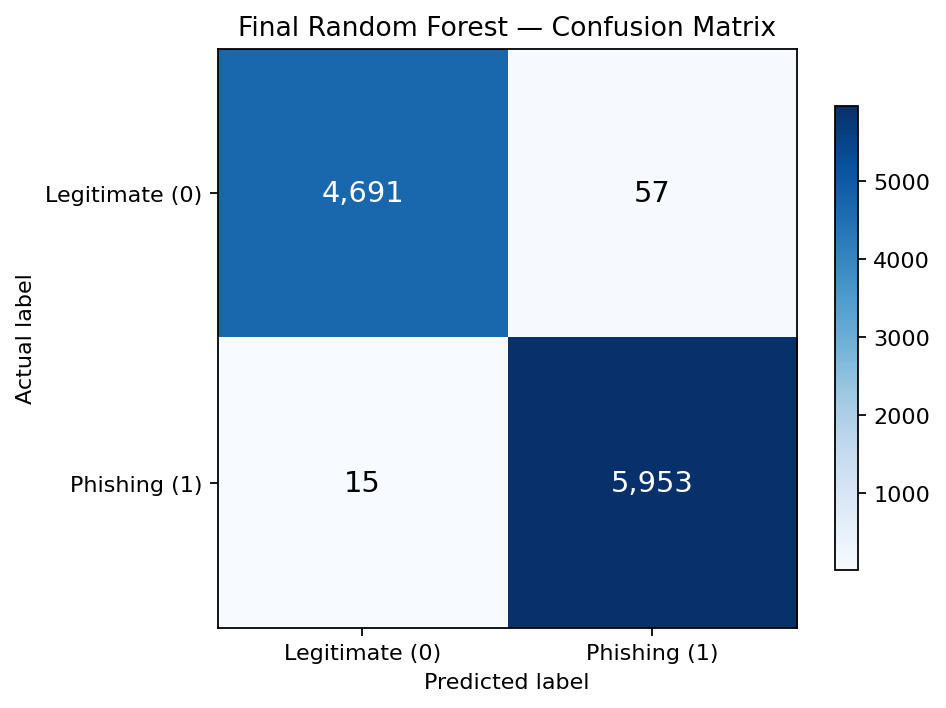

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6.1, 4.7))
ConfusionMatrixDisplay(
    confusion_matrix=final_cm_13g,
    display_labels=["Legitimate (0)", "Phishing (1)"]
).plot(ax=ax, cmap="Blues", colorbar=True, values_format="d")
ax.set_title("Final Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()


### Figure 2. Comparison of false positives and false negatives

The five-case reduction in false positives was achieved without an increase in false negatives, meeting the intervention's specified error-balance criterion.

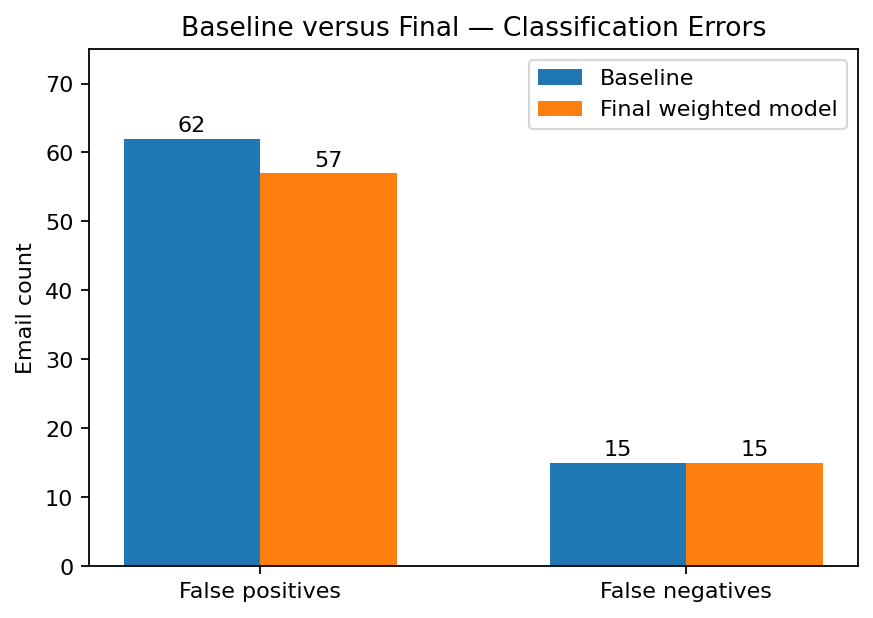

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

error_types = ["False positives", "False negatives"]
positions = np.arange(2)
width = 0.32
fig, ax = plt.subplots(figsize=(6.2, 4.2))
baseline_bars = ax.bar(positions - width/2, [baseline_FP_13g, baseline_FN_13g], width, label="Baseline")
final_bars = ax.bar(positions + width/2, [final_FP_13g, final_FN_13g], width, label="Final weighted model")
ax.bar_label(baseline_bars, padding=3)
ax.bar_label(final_bars, padding=3)
ax.set_xticks(positions, error_types)
ax.set_ylabel("Email count")
ax.set_title("Baseline versus Final — Classification Errors")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Receiver operating characteristic (ROC) analysis

**Figure 3. Baseline and final Random Forest ROC curves**

The ROC curves are calculated from the saved class-probability outputs when the notebook is executed. The recorded baseline ROC-AUC is **0.99911353**; the original evaluation code computes the final ROC-AUC from the final model's predictions. No curve is estimated from the summary AUC value alone.

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr_base, tpr_base, _ = roc_curve(y_test_array_13g, baseline_prob_13g)
fpr_final, tpr_final, _ = roc_curve(y_test_array_13g, final_prob_13g)

fig, ax = plt.subplots(figsize=(6.1, 4.8))
ax.plot(fpr_base, tpr_base, label=f"Locked baseline (AUC = {baseline_auc_13g:.6f})")
ax.plot(fpr_final, tpr_final, label=f"Final weighted model (AUC = {final_auc_13g:.6f})")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="Chance")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Random Forest — ROC Comparison")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 5. Discussion and conclusion

The final Random Forest experiment incorporated nine validated, counterfactual-guided legitimate-email examples into the original training representation through weighted retraining. The original training observations, labels, TF-IDF vocabulary, and Random Forest hyperparameters were preserved. The additional examples were assigned weight **7** each to strengthen the model's treatment of the targeted legitimate-email patterns.

On the evaluated 10,716-email dataset, false positives decreased from **62 to 57**, representing an **8.06% reduction**, while false negatives remained unchanged at **15**. The result meets the predefined experimental objective and shows that the targeted intervention improved the model's handling of the identified error cases.

The intervention was informed by the evaluated false-positive cases. Consequently, its measured effect should be interpreted within that evaluation design; assessment on a separate, previously untouched dataset remains necessary to establish broader generalization.